MD# 01 · Quality control (test run)

Summarises `results/04_QC_per_sample.csv`, written by `R/04_qc_doublets.R`.

**Rule (same for every sample, set in `R/utils.R`):** genes ≥ 500, UMIs ≥ 1,000, mito < 10 % **and** ≤ sample median + 3 MAD (floor 1 %), genes ≤ sample median + 3 MAD, doublets removed with scDblFinder, samples with < 100 nuclei left are dropped.

Test run: at most 300 nuclei loaded per sample (`max_cells_per_sample = 300`).

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
# Notebooks run from the project root so that results/ and config/ resolve.
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
qc = pd.read_csv("results/04_QC_per_sample.csv")
print(f"{len(qc)} samples, {qc.dataset.nunique()} datasets")
tot = qc[["n_loaded","n_pass_qc","n_doublets","n_kept"]].sum()
print(tot.to_string()); print(f"kept overall: {tot.n_kept/tot.n_loaded:.1%};  dropped samples (<100 nuclei): {qc.dropped_sample.sum()}")

322 samples, 11 datasets
n_loaded      96019
n_pass_qc     71002
n_doublets     3023
n_kept        67979
kept overall: 70.8%;  dropped samples (<100 nuclei): 37


In [3]:
by = qc.groupby("dataset").agg(samples=("sample_key","size"), loaded=("n_loaded","sum"), pass_qc=("n_pass_qc","sum"),
        doublets=("n_doublets","sum"), kept=("n_kept","sum"), dropped_samples=("dropped_sample","sum"),
        median_genes=("median_features","median"), median_UMIs=("median_counts","median"), median_pct_mt=("median_pct_mt","median"))
by["pct_kept"] = (100*by.kept/by.loaded).round(1)
by.sort_values("pct_kept")

,samples,loaded,pass_qc,doublets,kept,dropped_samples,median_genes,median_UMIs,median_pct_mt,pct_kept
dataset,,,,,,,,,,
GSE184950,34,10200,3044,60,2984,20,1409.00,2634.00,5.940,29.3
GSE178146,28,8400,3718,22,3696,6,1529.00,2513.00,1.250,44.0
GSE253462,41,12300,7260,187,7073,10,1300.00,1938.00,0.290,57.5
GSE193688,34,10200,7661,513,7148,1,2674.00,6682.00,0.180,70.1
GSE161045,12,3600,2689,143,2546,0,2358.50,4630.25,0.900,70.7
GSE235330,12,3600,2840,205,2635,0,1575.75,2600.50,0.870,73.2
GSE148434,12,3600,2969,205,2764,0,1645.00,2963.50,1.610,76.8
GSE202210,12,3600,3170,182,2988,0,2554.50,5580.00,0.275,83.0
GSE243639,29,8700,7762,273,7489,0,2545.00,5586.00,0.780,86.1


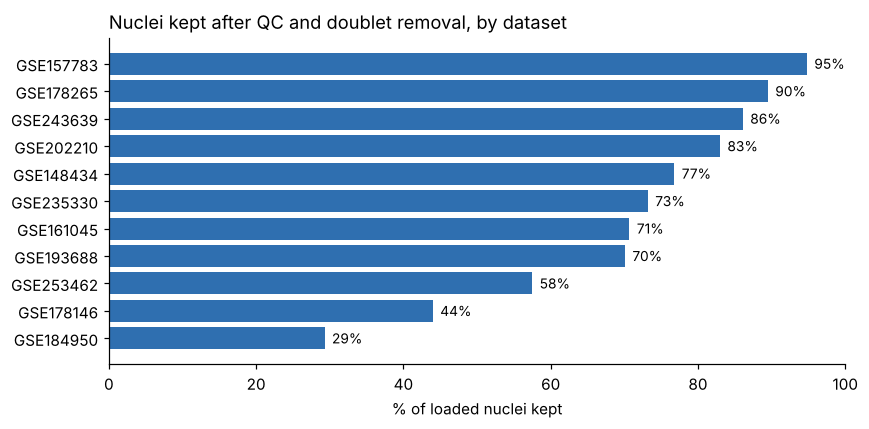

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
b = by.sort_values("pct_kept")
ax.barh(b.index, b.pct_kept, color="#2f6fb0"); ax.set_xlabel("% of loaded nuclei kept"); ax.set_xlim(0, 100)
for i, v in enumerate(b.pct_kept): ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_title("Nuclei kept after QC and doublet removal, by dataset", loc="left"); plt.tight_layout(); plt.show()

MD**Reading:** the shallow datasets (low median genes/UMIs) lose the most nuclei under the 500-gene / 1,000-UMI floor. In the full run each sample keeps all its nuclei, so far fewer samples will fall below 100.